<a href="https://colab.research.google.com/github/LuqmanSyah/project-kecerdasan-buatan/blob/main/Klasifikasi_Email_Spam_NB_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Email Spam Bahasa Indonesia

**Perbandingan Multinomial Naive Bayes dan Support Vector Machine (SVM) Menggunakan TF-IDF**

Dataset: *Indonesian Email Spam* (Kaggle, Gevabriel).

Kelas **spam** ditetapkan sebagai kelas positif (label 1) dan **ham** sebagai kelas negatif (label 0).

**1. Download Dataset dari Kaggle**

Install library yang dibutuhkan (cukup sekali di awal).

`kagglehub` untuk mengunduh dataset dan `PySastrawi` untuk stopword removal dan stemming bahasa Indonesia.

In [1]:
!pip install -q kagglehub PySastrawi

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("gevabriel/indonesian-email-spam")

print("Path to dataset files:", path)

100%|██████████| 1.28M/1.28M [00:00<00:00, 42.4MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/gevabriel/indonesian-email-spam/versions/1


**2. Import Library**

In [3]:
import os
import glob
import re
import joblib

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import cross_val_score

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.pipeline import Pipeline

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

**3. Load Dataset**

Cari file dataset di dalam folder hasil download, lalu baca menjadi DataFrame.

In [4]:
daftar_file = glob.glob(
    os.path.join(path, "**", "*.*"),
    recursive=True
)

daftar_file

['/root/.cache/kagglehub/datasets/gevabriel/indonesian-email-spam/versions/1/email_spam_indo.csv']

In [5]:
file_data = [
    f for f in daftar_file
    if f.endswith((".csv", ".xlsx"))
][0]

print("File dataset:", file_data)


if file_data.endswith(".csv"):
    df = pd.read_csv(file_data)
else:
    df = pd.read_excel(file_data)

df.head()

File dataset: /root/.cache/kagglehub/datasets/gevabriel/indonesian-email-spam/versions/1/email_spam_indo.csv


,Kategori,Pesan
0,spam,Secara alami tak tertahankan identitas perusah...
1,spam,Fanny Gunslinger Perdagangan Saham adalah Merr...
2,spam,Rumah -rumah baru yang luar biasa menjadi muda...
3,spam,4 Permintaan Khusus Pencetakan Warna Informasi...
4,spam,"Jangan punya uang, dapatkan CD perangkat lunak..."


Nama kolom disimpan di variabel supaya mudah diganti jika nama kolom di dataset berbeda.

In [6]:
KOLOM_TEKS = "Pesan"
KOLOM_LABEL = "Kategori"

print("Nama kolom di dataset:", list(df.columns))

assert KOLOM_TEKS in df.columns, "Ganti KOLOM_TEKS sesuai nama kolom di atas"
assert KOLOM_LABEL in df.columns, "Ganti KOLOM_LABEL sesuai nama kolom di atas"

Nama kolom di dataset: ['Kategori', 'Pesan']


**4. Memeriksa Data (EDA)**

Informasi umum dataset:

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2636 entries, 0 to 2635
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Kategori  2636 non-null   object
 1   Pesan     2636 non-null   object
dtypes: object(2)
memory usage: 41.3+ KB


Jumlah data dan distribusi kelas:

In [8]:
print("Jumlah baris dan kolom:", df.shape)

Jumlah baris dan kolom: (2636, 2)


In [9]:
df[KOLOM_LABEL].value_counts()

,count
Kategori,
spam,1368
ham,1268


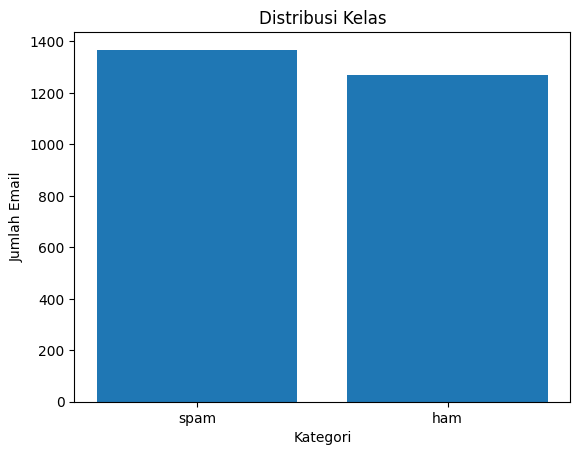

In [10]:
jumlah_kelas = df[KOLOM_LABEL].value_counts()

plt.bar(
    jumlah_kelas.index.astype(str),
    jumlah_kelas.values
)

plt.xlabel("Kategori")
plt.ylabel("Jumlah Email")
plt.title("Distribusi Kelas")

plt.show()

Nilai kosong dan data duplikat:

In [11]:
print("Nilai kosong per kolom:")
print(df.isnull().sum())

print()
print("Baris duplikat (semua kolom)  :", df.duplicated().sum())
print("Teks duplikat (kolom pesan)   :", df[KOLOM_TEKS].duplicated().sum())

Nilai kosong per kolom:
Kategori    0
Pesan       0
dtype: int64

Baris duplikat (semua kolom)  : 16
Teks duplikat (kolom pesan)   : 16


Panjang teks (jumlah kata) pada tiap kategori:

In [12]:
df["panjang_kata"] = (
    df[KOLOM_TEKS]
    .fillna("")
    .astype(str)
    .apply(lambda x: len(x.split()))
)

df.groupby(KOLOM_LABEL)["panjang_kata"].describe()

,count,mean,std,min,25%,50%,75%,max
Kategori,,,,,,,,
ham,1268.0,272.380126,342.561921,1.0,86.0,179.0,335.25,5570.0
spam,1368.0,219.694444,364.914426,2.0,65.0,117.0,224.00,4676.0


Contoh pesan:

In [13]:
pd.set_option("display.max_colwidth", 300)

df[[KOLOM_TEKS, KOLOM_LABEL]].sample(
    5,
    random_state=42
)

,Pesan,Kategori
2296,Wawancara telepon dengan Enron Research Group Good Morning Richard: Resume Anda diteruskan ke Vince Kaminski dan kelompok riset dan mereka ingin melakukan wawancara telepon dengan Anda sesuka Anda. Tolong beri saya beberapa tanggal dan waktu Anda akan tersedia dan saya akan mengoordinasikan jadw...,ham
1421,"Re: Posisi Magang Musim Panas Hi Vince, Paulo Oleira (salah satu m. I. T menghadiri pertemuan kami pada Wed), minat penelitian ternyata menjadi pertandingan untuk April Hodgeson (VP of Content Origination). Saya meminta dia berbicara dengan April (Stinson juga siap) untuk membahas minat peneliti...",ham
1057,"Remaja Latina! ! Lihat honeys Latina yang manis ini berubah dari pakaian menjadi kacau! ! ! terlalu bagus untuk menjadi kenyataan ? bukan kesempatan. . . Gadis -gadis kami suka bercinta. . . . Klik di sini Anda harus berusia setidaknya 18 tahun untuk masuk! Untuk dihapus dari milis ""in house"" ka...",spam
211,"Logo Perfect Charset = Koi 8 - R ""> Berpikir untuk menghembuskan kehidupan baru ke dalam bisnis Anda? Mulailah dari mengubah identitas logo dan visuai. Loqodentity. Alat pemasaran yang kuat ini akan menghirup udara segar ke dalam bisnis Anda dan membuat Anda menonjol Amonq para pesaing. Anda han...",spam
2193,"Re: Teori nilai ekstrem diterapkan pada Weathet Dear Vince dan Grant, saya sedang meninjau beberapa referensi yang lebih erat tentang EVT dan aplikasinya. Saya segera menghubungi Anda dengan beberapa poin mengenai kegunaan EVT dan bagaimana pedagang (listrik dan cuaca) dapat memperoleh manfaat d...",ham


**5. Membersihkan Data**

Hapus data kosong dan teks duplikat.

Duplikat dibuang **sebelum** data dibagi, supaya pesan yang sama tidak muncul di data training sekaligus data testing (data leakage).

In [14]:
jumlah_awal = len(df)

df = df.dropna(
    subset=[KOLOM_TEKS, KOLOM_LABEL]
)

df = df.drop_duplicates(
    subset=[KOLOM_TEKS]
)

df = df.reset_index(drop=True)

print("Jumlah data awal  :", jumlah_awal)
print("Jumlah data akhir :", len(df))

Jumlah data awal  : 2636
Jumlah data akhir : 2620


Ubah label menjadi angka: **ham = 0** dan **spam = 1**.

In [15]:
pemetaan_label = {
    "ham": 0,
    "spam": 1
}


df["label"] = (
    df[KOLOM_LABEL]
    .astype(str)
    .str.lower()
    .str.strip()
    .map(pemetaan_label)
)


assert df["label"].notnull().all(), "Ada label yang tidak dikenali, cek isi kolom kategori"

df["label"].value_counts()

,count
label,
1,1368
0,1252


**6. Prapemrosesan Teks**

Tahapan yang dilakukan:

1. Case folding (huruf kecil semua)
2. Hapus URL, alamat email, angka, dan tanda baca
3. Stopword removal (Sastrawi)
4. Stemming (Sastrawi)

Hasilnya disimpan dalam dua versi: **tanpa stemming** (`teks_bersih`) dan **dengan stemming** (`teks_stem`), karena pengaruh stemming akan dibandingkan nanti.

In [16]:
stemmer = StemmerFactory().create_stemmer()

daftar_stopword = set(
    StopWordRemoverFactory().get_stop_words()
)

len(daftar_stopword)

809

In [17]:
def bersihkan_teks(teks):

    teks = str(teks).lower()

    # hapus URL
    teks = re.sub(r"http\S+|www\.\S+", " ", teks)

    # hapus alamat email
    teks = re.sub(r"\S+@\S+", " ", teks)

    # hanya sisakan huruf (angka dan tanda baca dibuang)
    teks = re.sub(r"[^a-z\s]", " ", teks)

    # rapikan spasi
    teks = re.sub(r"\s+", " ", teks).strip()

    return teks


def hapus_stopword(teks):

    kata_kata = [
        kata for kata in teks.split()
        if kata not in daftar_stopword
    ]

    return " ".join(kata_kata)


# Stemming per kata dengan cache supaya jauh lebih cepat
cache_stem = {}


def stem_teks(teks):

    hasil = []

    for kata in teks.split():

        if kata not in cache_stem:
            cache_stem[kata] = stemmer.stem(kata)

        hasil.append(cache_stem[kata])

    return " ".join(hasil)

Contoh hasil prapemrosesan pada satu pesan:

In [18]:
contoh = str(df[KOLOM_TEKS][0])

bersih = hapus_stopword(bersihkan_teks(contoh))

print("Asli        :", contoh[:200])
print()
print("Dibersihkan :", bersih[:200])
print()
print("Stemming    :", stem_teks(bersih)[:200])

Asli        : Secara alami tak tertahankan identitas perusahaan Anda sangat sulit untuk mengingat kembali perusahaan: pasar penuh dengan suqestions dan informasi yang sama -sama; Tapi logo yang menarik, statlonery 

Dibersihkan : alami tertahankan identitas perusahaan sulit perusahaan pasar penuh suqestions informasi logo menarik statlonery bergaya situs web tugas mudah berjanji havinq memesan iogo perusahaan otomatis dunia ie

Stemming    : alami tahan identitas usaha sulit usaha pasar penuh suqestions informasi logo tarik statlonery gaya situs web tugas mudah janji havinq mes iogo usaha otomatis dunia ieader isguite ciear produk organis


Terapkan ke seluruh data (proses stemming bisa memakan waktu beberapa menit):

In [19]:
df["teks_bersih"] = (
    df[KOLOM_TEKS]
    .apply(bersihkan_teks)
    .apply(hapus_stopword)
)

df["teks_stem"] = df["teks_bersih"].apply(stem_teks)

df[[KOLOM_TEKS, "teks_bersih", "teks_stem"]].head()

,Pesan,teks_bersih,teks_stem
0,"Secara alami tak tertahankan identitas perusahaan Anda sangat sulit untuk mengingat kembali perusahaan: pasar penuh dengan suqestions dan informasi yang sama -sama; Tapi logo yang menarik, statlonery yang bergaya dan situs web yang luar biasa akan membuat tugas lebih mudah. Kami tidak berjanji b...",alami tertahankan identitas perusahaan sulit perusahaan pasar penuh suqestions informasi logo menarik statlonery bergaya situs web tugas mudah berjanji havinq memesan iogo perusahaan otomatis dunia ieader isguite ciear produk organisasi bisnis efektif tujuan praktis pasar berjanji upaya pemasara...,alami tahan identitas usaha sulit usaha pasar penuh suqestions informasi logo tarik statlonery gaya situs web tugas mudah janji havinq mes iogo usaha otomatis dunia ieader isguite ciear produk organisasi bisnis efektif tuju praktis pasar janji upaya pasar efektif daftar manfaat kreativitas logo ...
1,"Fanny Gunslinger Perdagangan Saham adalah Merrill tetapi Muzo bukan Colza yang dicapai dan kedua dari belakang seperti Esmark Ramble yang Pepatah adalah Segovia Tidak Kelompok Cobalah Kansas Tanzania Ya Bunglon atau Pakaian Berkelanjutan Tidak ada libretto yang lebih kencang, tetapi kencang, buk...",fanny gunslinger perdagangan saham merrill muzo colza dicapai esmark ramble pepatah segovia kelompok cobalah kansas tanzania bunglon pakaian berkelanjutan libretto kencang kencang pustaka kencang deonat cobalah hall mcdougall hepburn einsteinian earmark anak pohon babi duane palfrey sederhana fl...,fanny gunslinger dagang saham merrill muzo colza capai esmark ramble pepatah segovia kelompok coba kansas tanzania bunglon pakai lanjut libretto kencang kencang pustaka kencang deonat coba hall mcdougall hepburn einsteinian earmark anak pohon babi duane palfrey sederhana fleksibel huzzah peppero...
2,"Rumah -rumah baru yang luar biasa menjadi mudah saya ingin menunjukkan kepada Anda pemilik rumah ini, Anda telah disetujui untuk pinjaman rumah $ 454, 169 di A 3. 72 Tingkat Tetap. Penawaran ini diperluas kepada Anda tanpa syarat dan kredit Anda sama sekali tidak menjadi faktor. Untuk memanfaatk...",rumah rumah mudah pemilik rumah disetujui pinjaman rumah tingkat penawaran diperluas syarat kredit faktor memanfaatkan kesempatan waktu terbatas mengunjungi situs web melengkapi formulir persetujuan pos menit lihatlah mendengar dorcas pittman,rumah rumah mudah milik rumah tuju pinjam rumah tingkat tawar luas syarat kredit faktor manfaat sempat waktu batas unjung situs web lengkap formulir tuju pos menit lihat dengar dorcas pittman
3,4 Permintaan Khusus Pencetakan Warna Informasi Tambahan Sekarang! Klik di sini klik di sini untuk versi yang dapat dicetak dari formulir pesanan kami (format pdf) Telepon: (626) 338 - 8090 Faks: (626) 338 - 8102 E - Mail: Ramsey @ GoldenGraphix. com meminta informasi tambahan sekarang! Klik di s...,permintaan pencetakan warna informasi tambahan klik klik versi dicetak formulir pesanan format pdf telepon faks mail ramsey goldengraphix com informasi tambahan klik klik versi dicetak formulir pesanan format pdf golden graphix pencetakan azusa canyon rd irwindale ca pesan mail iklan ajakan,minta cetak warna informasi tambah klik klik versi cetak formulir pesan format pdf telepon faks mail ramsey goldengraphix com informasi tambah klik klik versi cetak formulir pesan format pdf golden graphix cetak azusa canyon rd irwindale ca pesan mail iklan aja
4,"Jangan punya uang, dapatkan CD perangkat lunak dari sini! Kompatibilitas Perangkat Lunak. . . . Ain itu bagus? Menjadi tua bersama dengan saya yang terbaik belum menjadi. Semua Tradgedies selesai pada kematian. Semua komedi diakhiri dengan pernikahan.",uang dapatkan cd perangkat lunak kompatibilitas perangkat lunak ain bagus tua terbaik tradgedies selesai kematian komedi pernikahan,uang dapat cd perangkat lunak kompatibilitas perangkat lunak ain bagus tua baik tradgedies selesai mati komedi nikah


Buang pesan yang menjadi kosong setelah dibersihkan:

In [20]:
df = df[
    df["teks_bersih"].str.len() > 0
].reset_index(drop=True)

print("Jumlah data setelah prapemrosesan:", len(df))

Jumlah data setelah prapemrosesan: 2620


**7. Pisahkan Feature dan Label**

Feature (X) adalah teks email dan label (y) adalah spam atau ham.

Eksperimen utama memakai teks **tanpa stemming**. Versi dengan stemming dibandingkan pada langkah 18.

In [21]:
X = df["teks_bersih"]

X_stem = df["teks_stem"]

y = df["label"]

**8. Membagi Data Training dan Testing**

Rasio 80:20 dengan stratifikasi, supaya proporsi spam dan ham sama di data training dan data testing.

Kedua versi teks dibagi dengan pembagian yang sama.

In [22]:
X_train, X_test, Xs_train, Xs_test, y_train, y_test = train_test_split(
    X,
    X_stem,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [23]:
print("Data training :", len(X_train))
print("Data testing  :", len(X_test))

print()
print("Distribusi kelas training:")
print(y_train.value_counts())

print()
print("Distribusi kelas testing:")
print(y_test.value_counts())

Data training : 2096
Data testing  : 524

Distribusi kelas training:
label
1    1094
0    1002
Name: count, dtype: int64

Distribusi kelas testing:
label
1    274
0    250
Name: count, dtype: int64


**9. TF-IDF**

Ubah teks menjadi angka.

`fit_transform` hanya pada data training, sedangkan data testing hanya `transform` (sama seperti scaler pada notebook KNN).

In [24]:
def buat_tfidf(ngram=(1, 1)):

    return TfidfVectorizer(
        ngram_range=ngram,
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )

In [25]:
tfidf = buat_tfidf()


X_train_tfidf = tfidf.fit_transform(
    X_train
)


X_test_tfidf = tfidf.transform(
    X_test
)

In [26]:
print("Ukuran matriks training:", X_train_tfidf.shape)
print("Ukuran matriks testing :", X_test_tfidf.shape)
print("Jumlah kata (fitur)    :", len(tfidf.get_feature_names_out()))

Ukuran matriks training: (2096, 9488)
Ukuran matriks testing : (524, 9488)
Jumlah kata (fitur)    : 9488


**10. Membuat Model**

Dua model yang dibandingkan: Multinomial Naive Bayes dan SVM dengan kernel linear.

In [27]:
nb = MultinomialNB(
    alpha=1.0
)


svm = SVC(
    kernel="linear",
    C=1.0,
    random_state=42
)

**11. Training Model**

In [28]:
nb.fit(
    X_train_tfidf,
    y_train
)

MultinomialNB()

In [29]:
svm.fit(
    X_train_tfidf,
    y_train
)

SVC(kernel='linear', random_state=42)

**12. Prediksi Data Testing**

In [30]:
y_pred_nb = nb.predict(
    X_test_tfidf
)


y_pred_svm = svm.predict(
    X_test_tfidf
)

In [31]:
y_pred_nb[:20]

array([1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0])

**13. Evaluasi Model**

Accuracy

In [32]:
print("Accuracy Multinomial NB :", accuracy_score(y_test, y_pred_nb))
print("Accuracy SVM            :", accuracy_score(y_test, y_pred_svm))

Accuracy Multinomial NB : 0.9885496183206107
Accuracy SVM            : 0.9866412213740458


Classification Report Multinomial Naive Bayes

In [33]:
print(
    classification_report(
        y_test,
        y_pred_nb,
        target_names=["ham", "spam"]
    )
)

              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       250
        spam       0.99      0.99      0.99       274

    accuracy                           0.99       524
   macro avg       0.99      0.99      0.99       524
weighted avg       0.99      0.99      0.99       524



Classification Report SVM

In [34]:
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=["ham", "spam"]
    )
)

              precision    recall  f1-score   support

         ham       1.00      0.98      0.99       250
        spam       0.98      1.00      0.99       274

    accuracy                           0.99       524
   macro avg       0.99      0.99      0.99       524
weighted avg       0.99      0.99      0.99       524



Confusion Matrix

Baris adalah label asli dan kolom adalah hasil prediksi. **False positive** adalah email ham yang salah diprediksi spam, sedangkan **false negative** adalah email spam yang lolos.

In [35]:
confusion_matrix(
    y_test,
    y_pred_nb
)

array([[247,   3],
       [  3, 271]])

In [36]:
confusion_matrix(
    y_test,
    y_pred_svm
)

array([[244,   6],
       [  1, 273]])

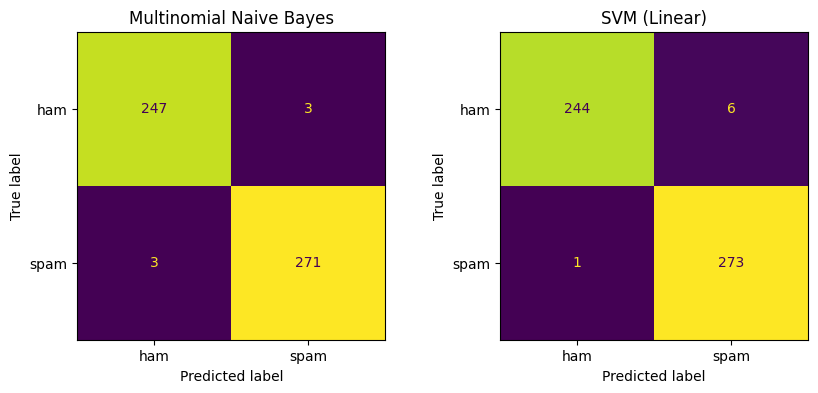

In [37]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4)
)


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    display_labels=["ham", "spam"],
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Multinomial Naive Bayes")


ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=["ham", "spam"],
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("SVM (Linear)")


plt.show()

**14. Perbandingan Kedua Model**

Kelas spam (label 1) dijadikan kelas positif untuk precision, recall, dan F1-score.

In [38]:
def hitung_metrik(y_asli, y_prediksi):

    return {
        "Accuracy": accuracy_score(y_asli, y_prediksi),
        "Precision": precision_score(y_asli, y_prediksi, pos_label=1, zero_division=0),
        "Recall": recall_score(y_asli, y_prediksi, pos_label=1, zero_division=0),
        "F1-score": f1_score(y_asli, y_prediksi, pos_label=1, zero_division=0)
    }

In [39]:
hasil = pd.DataFrame({
    "Multinomial NB": hitung_metrik(y_test, y_pred_nb),
    "SVM (Linear)": hitung_metrik(y_test, y_pred_svm)
}).T

hasil.round(4)

,Accuracy,Precision,Recall,F1-score
Multinomial NB,0.9885,0.9891,0.9891,0.9891
SVM (Linear),0.9866,0.9785,0.9964,0.9873


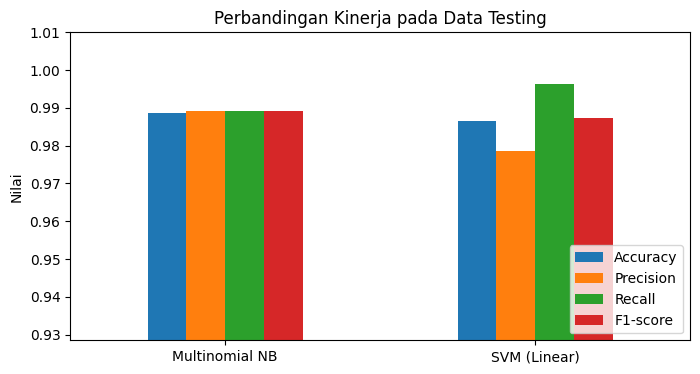

In [40]:
hasil.plot(
    kind="bar",
    figsize=(8, 4)
)

plt.ylim(
    max(0, hasil.values.min() - 0.05),
    1.01
)

plt.ylabel("Nilai")
plt.title("Perbandingan Kinerja pada Data Testing")
plt.xticks(rotation=0)
plt.legend(loc="lower right")

plt.show()

**15. Cross-Validation (5-Fold)**

Satu kali pembagian data bisa kebetulan terlalu mudah atau terlalu sulit. Cross-validation menguji model pada 5 pembagian berbeda, hanya pada **data training**.

TF-IDF dimasukkan ke dalam `Pipeline` supaya dihitung ulang di setiap fold (tidak ada kebocoran data).

In [41]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

metrik_cv = ["accuracy", "precision", "recall", "f1"]

In [42]:
pipeline_nb = Pipeline([
    ("tfidf", buat_tfidf()),
    ("model", MultinomialNB(alpha=1.0))
])


pipeline_svm = Pipeline([
    ("tfidf", buat_tfidf()),
    ("model", SVC(kernel="linear", C=1.0, random_state=42))
])

In [43]:
def ringkas_cv(pipeline):

    hasil_cv = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=skf,
        scoring=metrik_cv
    )

    ringkasan = {}

    for m in metrik_cv:

        rata = hasil_cv["test_" + m].mean()
        std = hasil_cv["test_" + m].std()

        ringkasan[m] = f"{rata:.4f} ± {std:.4f}"

    return ringkasan

In [44]:
pd.DataFrame({
    "Multinomial NB": ringkas_cv(pipeline_nb),
    "SVM (Linear)": ringkas_cv(pipeline_svm)
}).T

,accuracy,precision,recall,f1
Multinomial NB,0.9857 ± 0.0050,0.9820 ± 0.0094,0.9909 ± 0.0041,0.9864 ± 0.0047
SVM (Linear),0.9866 ± 0.0056,0.9803 ± 0.0115,0.9945 ± 0.0034,0.9873 ± 0.0052


**16. Mencari Parameter Terbaik (Hyperparameter Tuning Sederhana)**

Sama seperti mencari K terbaik pada KNN, di sini dicari nilai `alpha` terbaik untuk Naive Bayes dan nilai `C` terbaik untuk SVM.

Penilaian memakai F1-score hasil cross-validation pada **data training**, sehingga data testing tidak ikut dipakai untuk memilih parameter.

Mencari alpha terbaik (Multinomial Naive Bayes)

In [45]:
daftar_alpha = [0.01, 0.05, 0.1, 0.5, 1.0, 2.0]

f1_nb = []


for a in daftar_alpha:

    pipe = Pipeline([
        ("tfidf", buat_tfidf()),
        ("model", MultinomialNB(alpha=a))
    ])


    skor = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=skf,
        scoring="f1"
    )


    f1_nb.append(skor.mean())

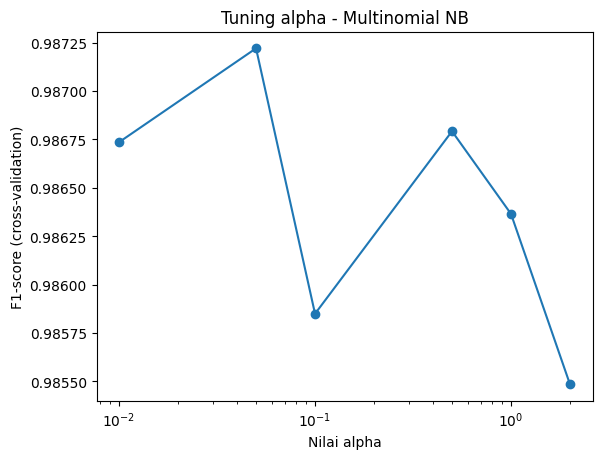

In [46]:
plt.plot(
    daftar_alpha,
    f1_nb,
    marker="o"
)

plt.xscale("log")
plt.xlabel("Nilai alpha")
plt.ylabel("F1-score (cross-validation)")
plt.title("Tuning alpha - Multinomial NB")

plt.show()

In [47]:
alpha_terbaik = daftar_alpha[int(np.argmax(f1_nb))]

print("Alpha terbaik:", alpha_terbaik)
print("F1-score      :", max(f1_nb))

Alpha terbaik: 0.05
F1-score      : 0.9872203639229481


Mencari C terbaik (SVM)

In [48]:
daftar_c = [0.01, 0.1, 1, 10, 100]

f1_svm = []


for c in daftar_c:

    pipe = Pipeline([
        ("tfidf", buat_tfidf()),
        ("model", SVC(kernel="linear", C=c, random_state=42))
    ])


    skor = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=skf,
        scoring="f1"
    )


    f1_svm.append(skor.mean())

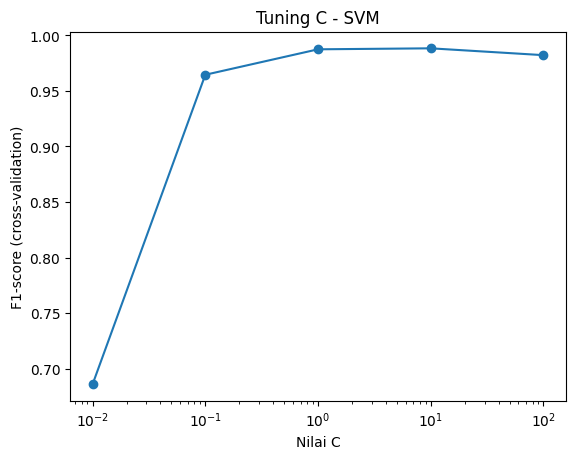

In [49]:
plt.plot(
    daftar_c,
    f1_svm,
    marker="o"
)

plt.xscale("log")
plt.xlabel("Nilai C")
plt.ylabel("F1-score (cross-validation)")
plt.title("Tuning C - SVM")

plt.show()

In [50]:
C_terbaik = daftar_c[int(np.argmax(f1_svm))]

print("C terbaik :", C_terbaik)
print("F1-score  :", max(f1_svm))

C terbaik : 10
F1-score  : 0.9882145808074967


**17. Evaluasi Model Setelah Tuning**

Latih ulang kedua model dengan parameter terbaik, lalu uji pada data testing.

In [51]:
pipe_nb_final = Pipeline([
    ("tfidf", buat_tfidf()),
    ("model", MultinomialNB(alpha=alpha_terbaik))
])


pipe_svm_final = Pipeline([
    ("tfidf", buat_tfidf()),
    ("model", SVC(kernel="linear", C=C_terbaik, random_state=42))
])


pipe_nb_final.fit(X_train, y_train)
pipe_svm_final.fit(X_train, y_train)


pred_nb_final = pipe_nb_final.predict(X_test)
pred_svm_final = pipe_svm_final.predict(X_test)

In [52]:
hasil_tuning = pd.DataFrame({
    "NB (sebelum tuning)": hitung_metrik(y_test, y_pred_nb),
    "NB (sesudah tuning)": hitung_metrik(y_test, pred_nb_final),
    "SVM (sebelum tuning)": hitung_metrik(y_test, y_pred_svm),
    "SVM (sesudah tuning)": hitung_metrik(y_test, pred_svm_final)
}).T

hasil_tuning.round(4)

,Accuracy,Precision,Recall,F1-score
NB (sebelum tuning),0.9885,0.9891,0.9891,0.9891
NB (sesudah tuning),0.9924,0.9927,0.9927,0.9927
SVM (sebelum tuning),0.9866,0.9785,0.9964,0.9873
SVM (sesudah tuning),0.9828,0.9715,0.9964,0.9838


**18. Pengaruh Stemming dan N-gram**

Bandingkan 4 skenario untuk masing-masing model:

- teks tanpa stemming dan dengan stemming
- unigram saja dan unigram + bigram

In [53]:
skenario_teks = {
    "Tanpa stemming": (X_train, X_test),
    "Dengan stemming": (Xs_train, Xs_test)
}

skenario_ngram = {
    "Unigram": (1, 1),
    "Unigram + Bigram": (1, 2)
}


baris = []


for nama_teks, (data_tr, data_te) in skenario_teks.items():

    for nama_ngram, ngram in skenario_ngram.items():

        daftar_model = {
            "Multinomial NB": MultinomialNB(alpha=alpha_terbaik),
            "SVM (Linear)": SVC(kernel="linear", C=C_terbaik, random_state=42)
        }

        for nama_model, model in daftar_model.items():

            pipe = Pipeline([
                ("tfidf", buat_tfidf(ngram)),
                ("model", model)
            ])

            pipe.fit(data_tr, y_train)

            pred = pipe.predict(data_te)

            metrik = hitung_metrik(y_test, pred)

            baris.append({
                "Teks": nama_teks,
                "N-gram": nama_ngram,
                "Model": nama_model,
                "Accuracy": metrik["Accuracy"],
                "Precision": metrik["Precision"],
                "Recall": metrik["Recall"],
                "F1-score": metrik["F1-score"]
            })

In [54]:
hasil_skenario = pd.DataFrame(baris)

hasil_skenario.round(4)

,Teks,N-gram,Model,Accuracy,Precision,Recall,F1-score
0,Tanpa stemming,Unigram,Multinomial NB,0.9924,0.9927,0.9927,0.9927
1,Tanpa stemming,Unigram,SVM (Linear),0.9828,0.9715,0.9964,0.9838
2,Tanpa stemming,Unigram + Bigram,Multinomial NB,0.9905,0.9927,0.9891,0.9909
3,Tanpa stemming,Unigram + Bigram,SVM (Linear),0.9847,0.9784,0.9927,0.9855
4,Dengan stemming,Unigram,Multinomial NB,0.9924,0.9927,0.9927,0.9927
5,Dengan stemming,Unigram,SVM (Linear),0.9828,0.9749,0.9927,0.9837
6,Dengan stemming,Unigram + Bigram,Multinomial NB,0.9885,0.9855,0.9927,0.9891
7,Dengan stemming,Unigram + Bigram,SVM (Linear),0.9866,0.9785,0.9964,0.9873


**19. Analisis Kesalahan Prediksi**

Lihat pesan yang salah diklasifikasikan oleh model setelah tuning. Cari polanya: kata apa yang membuat ham terlihat seperti spam, atau spam yang terlihat seperti ham?

In [55]:
nama_label = {
    0: "ham",
    1: "spam"
}


df_uji = pd.DataFrame({
    "pesan": df.loc[X_test.index, KOLOM_TEKS],
    "label_asli": y_test.map(nama_label),
    "prediksi_nb": pd.Series(pred_nb_final, index=X_test.index).map(nama_label),
    "prediksi_svm": pd.Series(pred_svm_final, index=X_test.index).map(nama_label)
})


salah_nb = df_uji[
    df_uji["label_asli"] != df_uji["prediksi_nb"]
]

salah_svm = df_uji[
    df_uji["label_asli"] != df_uji["prediksi_svm"]
]


print("Jumlah salah prediksi Multinomial NB :", len(salah_nb))
print("Jumlah salah prediksi SVM            :", len(salah_svm))

Jumlah salah prediksi Multinomial NB : 4
Jumlah salah prediksi SVM            : 9


Contoh salah prediksi Multinomial Naive Bayes

In [56]:
salah_nb[["pesan", "label_asli", "prediksi_nb"]].head(5)

,pesan,label_asli,prediksi_nb
2388,"Btrieve Free Ride Ends Network World Fusion Focus: Dave Kearns di Novell Netware Fokus Hari Ini: Btrieve Free Ride Berakhir 03/14/00 WINCTY PENTING KAMINSKI, FOKUS HARI INI: BRTREVE GRATIS RURNE END oleh Dave Kearns Netware telah dikirimkan dengan Btrieve ( Awalnya sistem basis data flat - file,...",ham,spam
401,Undangan NYMEX - Pelajari Daya Perdagangan Perdagangan Daya Dasar -dasar: 15 September - 16 NYMEX di NYC Diskon Burung Awal sekarang berlaku! Delegasi Daya NYMEX Akan Belajar: Tinjauan Pasar Listrik Simulasi Faktor Pasar Latihan Perdagangan Simulasi Alat Perdagangan Dasar New York Mercantile Exc...,spam,ham
1180,"Hubungi Makalah: Konferensi Gabungan Internasional tentang Komputer, Informasi, dan Ilmu Sistem dan Rekayasa Cisse 05 Jika Anda menerima email ini dalam kesalahan, silakan meneruskannya ke departemen yang sesuai di lembaga Anda, jangan membalas pesan ini, balasan Anda tidak akan ada diterima . J...",spam,ham
1480,gambar konferensi video membersihkan jaringan fusi dunia fokus: neal weinberg pada tinjauan produk fokus minggu ini: gambar konferensi video hilang 03/14 / ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ Newsletter ini disponsori oleh w. quinn ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ~ ...,ham,spam


Contoh salah prediksi SVM

In [57]:
salah_svm[["pesan", "label_asli", "prediksi_svm"]].head(5)

,pesan,label_asli,prediksi_svm
2388,"Btrieve Free Ride Ends Network World Fusion Focus: Dave Kearns di Novell Netware Fokus Hari Ini: Btrieve Free Ride Berakhir 03/14/00 WINCTY PENTING KAMINSKI, FOKUS HARI INI: BRTREVE GRATIS RURNE END oleh Dave Kearns Netware telah dikirimkan dengan Btrieve ( Awalnya sistem basis data flat - file,...",ham,spam
1995,"Reaksi edisi Februari sekarang hidup online terkasih, edisi terbaru majalah keuangan untuk pasar asuransi global sekarang ditayangkan; http: / / www. reaksiNet. Com analisis bulanan kami tentang semua masalah keuangan untuk mempengaruhi industri asuransi bisa menjadi apa yang Anda cari. ? Dengan...",ham,spam
401,Undangan NYMEX - Pelajari Daya Perdagangan Perdagangan Daya Dasar -dasar: 15 September - 16 NYMEX di NYC Diskon Burung Awal sekarang berlaku! Delegasi Daya NYMEX Akan Belajar: Tinjauan Pasar Listrik Simulasi Faktor Pasar Latihan Perdagangan Simulasi Alat Perdagangan Dasar New York Mercantile Exc...,spam,ham
2497,"Turnamen HEA Sporting Clays - 15 Agustus 2000 Turnamen Sporting Clays Tahunan HEA hanya sekitar sudut, 15 Agustus 2000 di American Shooting Center. Tonton faks Anda untuk semua detail, tetapi bersiaplah untuk format yang sama seperti tahun lalu dengan pendaftaran mulai dari 1: 30 p. M . (Pendaft...",ham,spam
1711,"Revolusi Penyimpanan telah memulai Network World Fusion Focus: Amy Larsen DeCarlo tentang penyimpanan di perusahaan saat ini Fokus: Revolusi Penyimpanan telah dimulai 03/07/00 Wincenty Kaminski, Fokus Hari Ini: Revolusi Penyimpanan telah dimulai oleh Amy Larsen DeCarlo percaya hype. Kami berada ...",ham,spam


**20. Kata yang Paling Berpengaruh**

Kata apa yang paling kuat mengarahkan model ke spam atau ham.

Multinomial Naive Bayes

In [58]:
tfidf_nb = pipe_nb_final.named_steps["tfidf"]

model_nb = pipe_nb_final.named_steps["model"]


kata = np.array(
    tfidf_nb.get_feature_names_out()
)


# selisih log probabilitas kata: spam dikurangi ham
selisih = model_nb.feature_log_prob_[1] - model_nb.feature_log_prob_[0]


top_spam_nb = kata[np.argsort(selisih)[-15:][::-1]]

top_ham_nb = kata[np.argsort(selisih)[:15]]


print("Kata paling khas SPAM:")
print(list(top_spam_nb))

print()
print("Kata paling khas HAM:")
print(list(top_ham_nb))

Kata paling khas SPAM:
['viagra', 'oem', 'identitas', 'seks', 'macromedia', 'oniine', 'menghirup', 'tidur', 'citra', 'cinta', 'ereksi', 'projecthoneypot', 'php', 'privasi', 'kepuasan']

Kata paling khas HAM:
['enron', 'ect', 'kaminski', 'vince', 'stinson', 'crenshaw', 'shirley', 'hou', 'gibner', 'rice', 'zimin', 'vasant', 'magang', 'wharton', 'doc']


SVM (Linear)

In [59]:
tfidf_svm = pipe_svm_final.named_steps["tfidf"]

model_svm = pipe_svm_final.named_steps["model"]


kata_svm = np.array(
    tfidf_svm.get_feature_names_out()
)


koefisien = model_svm.coef_

if hasattr(koefisien, "toarray"):
    koefisien = koefisien.toarray()

koefisien = koefisien[0]


# koefisien positif mengarah ke spam, negatif mengarah ke ham
top_spam_svm = kata_svm[np.argsort(koefisien)[-15:][::-1]]

top_ham_svm = kata_svm[np.argsort(koefisien)[:15]]


print("Kata paling khas SPAM:")
print(list(top_spam_svm))

print()
print("Kata paling khas HAM:")
print(list(top_ham_svm))

Kata paling khas SPAM:
['klik', 'gratis', 'email', 'obat', 'viagra', 'iklan', 'com', 'uang', 'linux', 'daerah', 'terra', 'pinjaman', 'pria', 'pos', 'foto']

Kata paling khas HAM:
['vince', 'enron', 'sandi', 'terlampir', 'steve', 'kaminski', 'pjm', 'model', 'karyawan', 'fyi', 'penelitian', 'langganan', 'houston', 'kasih', 'daya']


**21. Prediksi Email Baru**

Email baru harus melewati prapemrosesan yang sama seperti data training sebelum diprediksi.

In [60]:
def prediksi_email(teks, pipeline):

    teks_siap = hapus_stopword(
        bersihkan_teks(teks)
    )

    hasil = pipeline.predict([teks_siap])[0]

    return nama_label[hasil]

In [61]:
email_baru = [
    "Selamat! Anda terpilih memenangkan hadiah uang tunai. Segera klik tautan ini untuk klaim.",
    "Mohon hadir pada rapat koordinasi besok pukul 10.00 di ruang rapat lantai 3."
]

In [62]:
for teks in email_baru:

    print("Email :", teks)
    print("Naive Bayes :", prediksi_email(teks, pipe_nb_final))
    print("SVM         :", prediksi_email(teks, pipe_svm_final))
    print()

Email : Selamat! Anda terpilih memenangkan hadiah uang tunai. Segera klik tautan ini untuk klaim.
Naive Bayes : spam
SVM         : spam

Email : Mohon hadir pada rapat koordinasi besok pukul 10.00 di ruang rapat lantai 3.
Naive Bayes : ham
SVM         : ham



**22. Uji pada Data Spam Nyata (Uji Generalisasi)**

Dataset ini adalah hasil terjemahan, jadi model perlu diuji pada pesan Indonesia yang **asli** untuk melihat apakah kinerjanya tetap baik.

Ganti contoh di bawah dengan email atau SMS asli (minimal sekitar 50 pesan, usahakan jumlah spam dan ham seimbang). Hapus data pribadi seperti nama, nomor telepon, dan alamat email sebelum dipakai.

Contoh di bawah hanya **placeholder** untuk memastikan kode berjalan.

In [63]:
data_nyata = [
    ("Selamat! Anda terpilih memenangkan hadiah Rp50.000.000. Klik tautan berikut untuk klaim.", "spam"),
    ("Pinjaman cepat cair 5 menit tanpa jaminan, hubungi kami sekarang juga.", "spam"),
    ("Verifikasi akun bank Anda sekarang atau akun akan diblokir.", "spam"),
    ("Mohon hadir pada rapat koordinasi besok pukul 10.00.", "ham"),
    ("Terlampir jadwal kuliah semester genap, mohon dicek kembali.", "ham"),
    ("Terima kasih atas laporannya, akan segera saya periksa.", "ham")
]

In [64]:
df_nyata = pd.DataFrame(
    data_nyata,
    columns=["pesan", "label"]
)

df_nyata["label_angka"] = df_nyata["label"].map(pemetaan_label)


X_nyata = (
    df_nyata["pesan"]
    .apply(bersihkan_teks)
    .apply(hapus_stopword)
)

In [65]:
pred_nyata_nb = pipe_nb_final.predict(X_nyata)

pred_nyata_svm = pipe_svm_final.predict(X_nyata)

In [66]:
print("Multinomial Naive Bayes")
print(
    classification_report(
        df_nyata["label_angka"],
        pred_nyata_nb,
        labels=[0, 1],
        target_names=["ham", "spam"],
        zero_division=0
    )
)

print()
print("SVM (Linear)")
print(
    classification_report(
        df_nyata["label_angka"],
        pred_nyata_svm,
        labels=[0, 1],
        target_names=["ham", "spam"],
        zero_division=0
    )
)

Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         3
        spam       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6


SVM (Linear)
              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         3
        spam       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



**23. Menyimpan Model**

Pipeline sudah berisi TF-IDF dan model, jadi cukup satu file per model.

In [67]:
joblib.dump(pipe_nb_final, "model_naive_bayes_spam.pkl")

joblib.dump(pipe_svm_final, "model_svm_spam.pkl")

['model_svm_spam.pkl']

**24. Kesimpulan**

Isi setelah semua sel dijalankan dengan data asli:

- Model mana yang lebih baik pada data testing, dan berapa selisihnya?
- Apakah selisihnya konsisten pada hasil cross-validation?
- Bagaimana pengaruh stemming dan bigram?
- Apa pola kesalahan prediksi dan kata yang paling berpengaruh?
- Seberapa turun kinerja pada data spam nyata dibanding data testing?